# Approach 1: Text-Window FNN

This notebook contains the selected combined method only. It opens the saved outputs without retraining. The model predicts whether an AI model will answer a task correctly, as a probability between zero and one.

In [1]:
from pathlib import Path
import json
import os
import sys

os.environ['KERAS_BACKEND'] = 'torch'
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'dharaneesh/training.py').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Open this notebook inside the dl-project repository.')
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
import pandas as pd
from IPython.display import Image, Markdown, display
HERE = REPO / 'dharaneesh'
DATA_DIR = Path(os.environ.get('AIMS_DATA_DIR', str(REPO.parent)))
print('Project folder:', HERE)
print('Dataset folder:', DATA_DIR)

Project folder: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh
Dataset folder: C:\Users\dhara\Downloads\aims\aims\data\measurement-db


## Architecture

Task text -> up to four selected 254-token windows -> frozen MiniLM SBERT -> normalized mean pooling (384 features).

Model name, provider, harness, harness version, and reasoning effort -> normalized feature hashing (256 features). Four text statistics describe length, newline count, digit proportion, and selected punctuation proportion.

The 644 inputs feed Dense(32, ReLU) -> Dropout(0.35) -> Dense(16, ReLU) -> Dropout(0.35) -> Dense(1, sigmoid). Hidden kernels use L2 = 0.0001. The network has 21,185 trainable parameters. The encoder remains frozen. There is no logistic replacement, ensemble, confidence shrinkage, or revealed-label adaptation.

In [2]:
config = json.loads((HERE / 'submission/config.json').read_text())
validation = json.loads((HERE / 'results/validation/summary.json').read_text())
display(pd.Series(config['method'], name='Selected FNN'))
print('Checkpoint selection: epoch', config['best_epoch'], 'of', config['epochs_completed'])
print('Fitting responses:', config['training_rows'])
print('Validation responses:', config['validation_rows'])

name         sbert_window_fnn_brier
features                      sbert
estimator                       fnn
loss                          brier
hidden                     [32, 16]
dropout                        0.35
l2                           0.0001
Name: Selected FNN, dtype: object

Checkpoint selection: epoch 12 of 16
Fitting responses: 109305
Validation responses: 26977


## Training and Validation

The four native item-level binary benchmarks contribute 136,282 responses. Items and model details are joined using validated many-to-one joins. Complete prompts are grouped before the 80/20 split (split seed 42), so duplicate prompts cannot cross the split. Fitting weights give each model-benchmark pair equal total influence.

Training uses Brier loss (MSE for binary labels), Adam with initial learning rate 0.0005, batch size 512, a maximum of 20 epochs, and early stopping with patience four. Checkpoints use pure equal-pair validation Brier, without the L2 penalty. ReduceLROnPlateau halves the rate after two epochs without a validation-Brier improvement of at least 0.0001, down to 0.00001. The saved seed-42 checkpoint is from epoch 12. The first reduction took effect in epoch 15, so it did not improve this run's selected checkpoint.

The following logs are the original completed run, not a fresh training session. Accuracy uses response weighting and a probability threshold of 0.5; Brier is the primary metric and lower is better.

,accuracy,brier_score,loss,val_accuracy,val_brier_score,val_loss,val_pair_brier,learning_rate,train_pair_brier,train_row_accuracy,val_row_accuracy,epoch
0,0.711400,0.203383,0.210098,0.704988,0.186167,0.192127,0.186167,0.00050,0.177636,0.673967,0.661082,1
1,0.724473,0.175930,0.181738,0.704929,0.174825,0.180553,0.174825,0.00050,0.163996,0.674141,0.661786,2
2,0.743443,0.163862,0.169608,0.744185,0.170221,0.176042,0.170221,0.00050,0.153902,0.698742,0.661489,3
3,0.772157,0.155427,0.161377,0.752795,0.166239,0.172336,0.166239,0.00050,0.145626,0.699657,0.661267,4
4,0.789705,0.148673,0.154940,0.755473,0.165420,0.171857,0.165420,0.00050,0.139043,0.703856,0.662379,5
5,0.800052,0.143597,0.150205,0.761059,0.163168,0.169895,0.163168,0.00050,0.133466,0.706390,0.663676,6
6,0.809206,0.138839,0.145717,0.751448,0.164444,0.171458,0.164444,0.00050,0.129415,0.707781,0.660563,7
7,0.814924,0.135466,0.142632,0.760891,0.162910,0.170215,0.162910,0.00050,0.125984,0.709464,0.663528,8
8,0.816863,0.132522,0.139958,0.753941,0.163681,0.171236,0.163681,0.00050,0.123061,0.711733,0.664270,9
9,0.821688,0.130833,0.138534,0.756380,0.162804,0.170627,0.162803,0.00050,0.119331,0.711660,0.660711,10


,seed,row_brier,pair_brier,accuracy,row_ece,pairs,rows,best_epoch,epochs_completed,training_seconds
0,42,0.191507,0.161935,0.664010,0.057952,147,26977,12,16,29.808062
1,123,0.191404,0.161200,0.659339,0.060816,147,26977,6,10,18.261842
2,2026,0.193767,0.160535,0.662601,0.068763,147,26977,6,10,18.798839


row_brier                       0.191507
pair_brier                      0.161935
accuracy                        0.664010
row_ece                         0.057952
pairs                         147.000000
rows                        26977.000000
best_epoch                     12.000000
epochs_completed               16.000000
training_seconds               29.808062
checkpoint_parity_cases         8.000000
training_rows              109305.000000
validation_rows             26977.000000
Name: Seed-42 selected checkpoint, dtype: float64

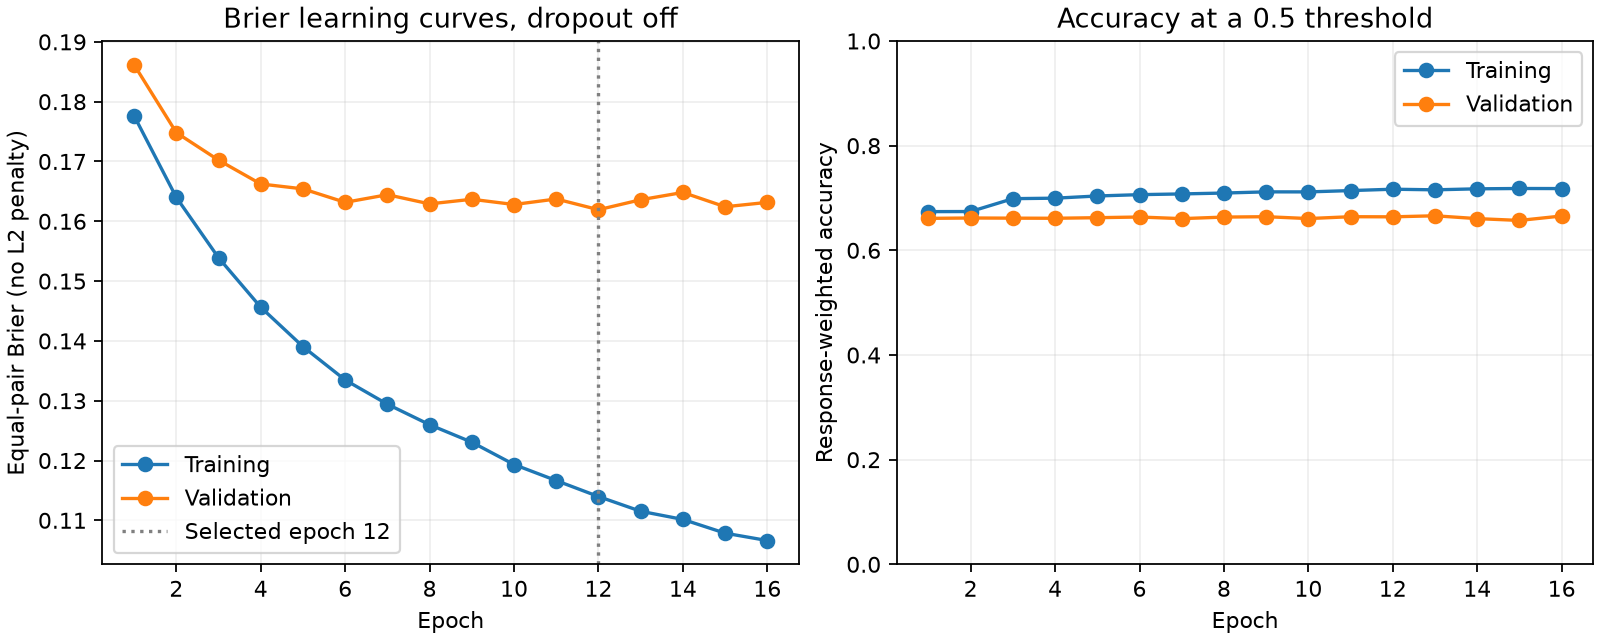

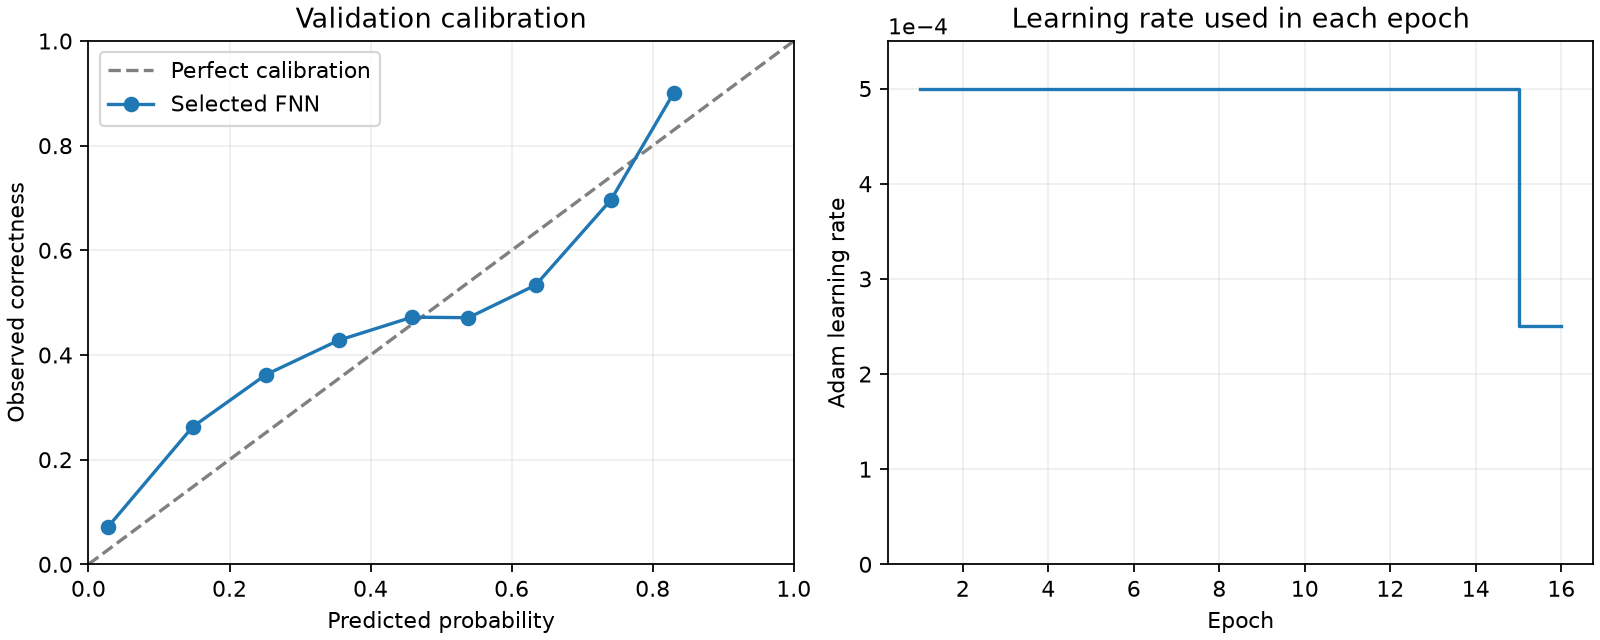

In [3]:
history = pd.read_csv(HERE / 'results/validation/history.csv')
display(history.round(6))
display(pd.read_csv(HERE / 'results/validation/seed_results.csv').round(6))
display(pd.Series(validation, name='Seed-42 selected checkpoint'))
display(Image(filename=str(HERE / 'results/validation/learning_curves.png')))
display(Image(filename=str(HERE / 'results/validation/calibration_and_lr.png')))

## LOBO Results

Four-fold leave-one-benchmark-out evaluation holds out one entire benchmark at a time. The remaining benchmarks have their own prompt-grouped 80/20 fitting and checkpoint-selection split. The outer benchmark and duplicate outer-test prompts are excluded from both. Each fold starts with fresh weights. This reuses the existing LOBO procedure.

The packaged checkpoint is not a LOBO fold model. LOBO evaluates the same recipe through four separate fits, using initialization seed 42. These are public development results, not hidden CodaBench results.

,pair_brier,benchmark_mean_brier,row_brier,row_accuracy,pairs,rows,benchmarks
FNN,0.261456,0.284305,0.299075,0.546433,147.0,136282.0,4.0
Training mean,0.231825,0.257348,0.282284,0.671417,147.0,136282.0,4.0
Constant 0.5,0.250000,0.250000,0.250000,0.328583,147.0,136282.0,4.0


,held_out,predictor,row_brier,pair_brier,accuracy,row_ece,pairs,rows
0,multi_swebench,FNN,0.248523,0.256837,0.560897,0.303505,82,57975
1,multi_swebench,Training mean,0.227538,0.232376,0.852057,0.318562,82,57975
2,multi_swebench,Constant 0.5,0.250000,0.250000,0.147943,0.352057,82,57975
3,real_webagents,FNN,0.249967,0.249450,0.639020,0.142440,33,4449
4,real_webagents,Training mean,0.230559,0.229707,0.642392,0.028878,33,4449
5,real_webagents,Constant 0.5,0.250000,0.250000,0.357608,0.142392,33,4449
6,researchcodebench,FNN,0.287038,0.283689,0.631044,0.219396,31,6784
7,researchcodebench,Training mean,0.232063,0.229195,0.638709,0.036100,31,6784
8,researchcodebench,Constant 0.5,0.250000,0.250000,0.361291,0.138709,31,6784
9,swe_rebench,FNN,0.347245,0.347245,0.519232,0.296867,1,67074


,held_out,training_rows,validation_rows,test_rows,training_prompts,validation_prompts,test_prompts,duplicate_test_prompt_rows_removed_from_pool,best_epoch,epochs_completed,training_seconds,training_mean_probability,checkpoint_parity_cases
0,multi_swebench,62203,16104,57975,5372,1344,2078,0,9,13,13.704693,0.466505,8
1,real_webagents,105728,26105,4449,6848,1713,233,0,4,8,15.288243,0.328730,8
2,researchcodebench,104022,25476,6784,6865,1717,212,0,5,9,15.582590,0.325191,8
3,swe_rebench,55272,13936,67074,2018,505,6271,0,13,17,15.402060,0.181937,8


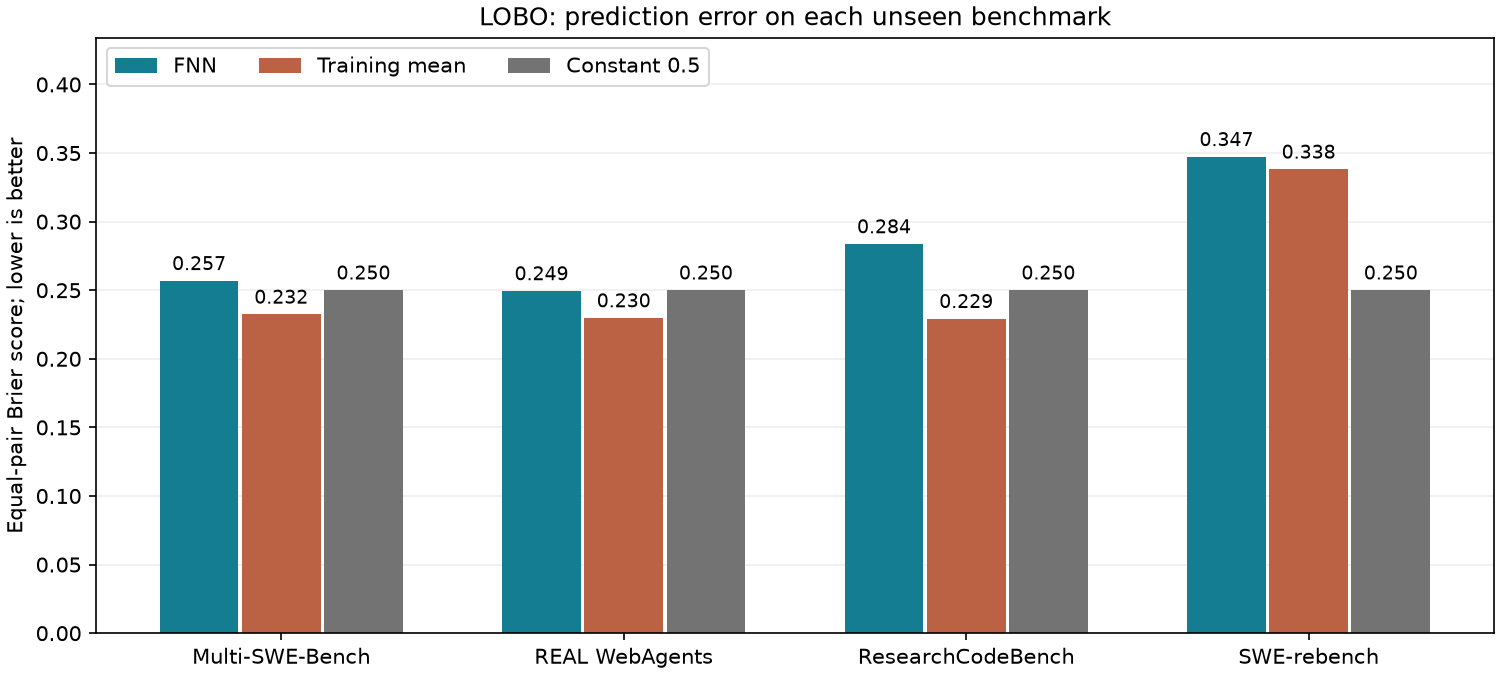

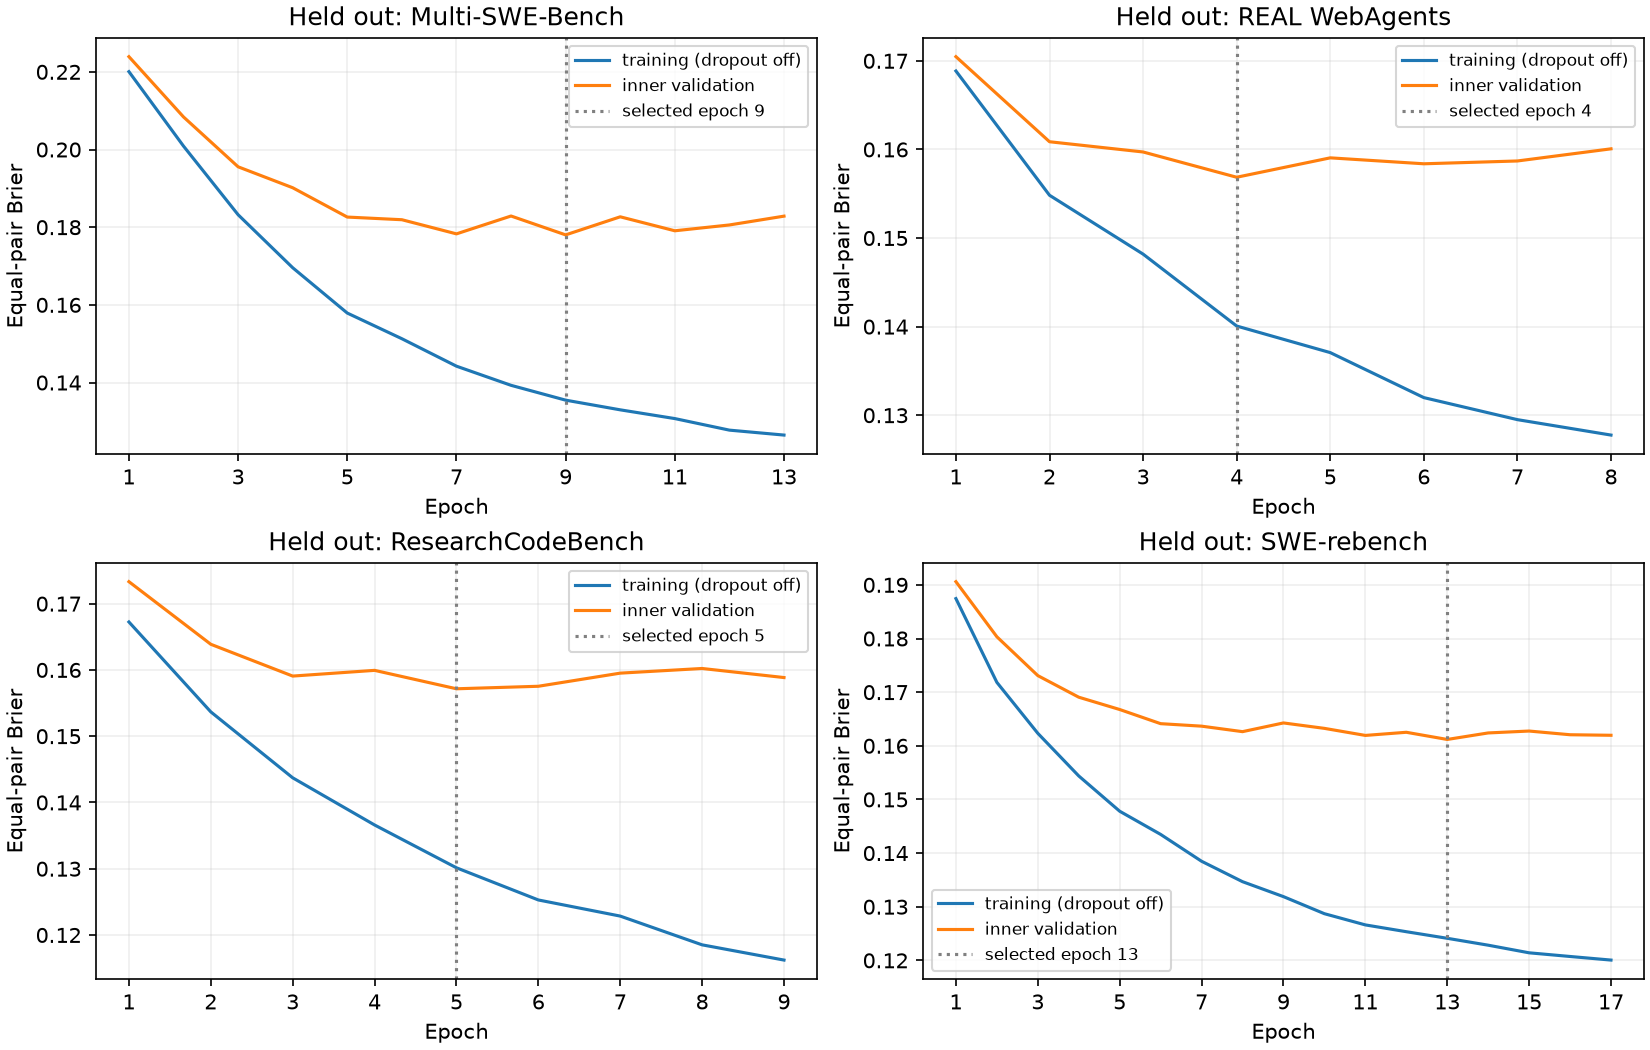

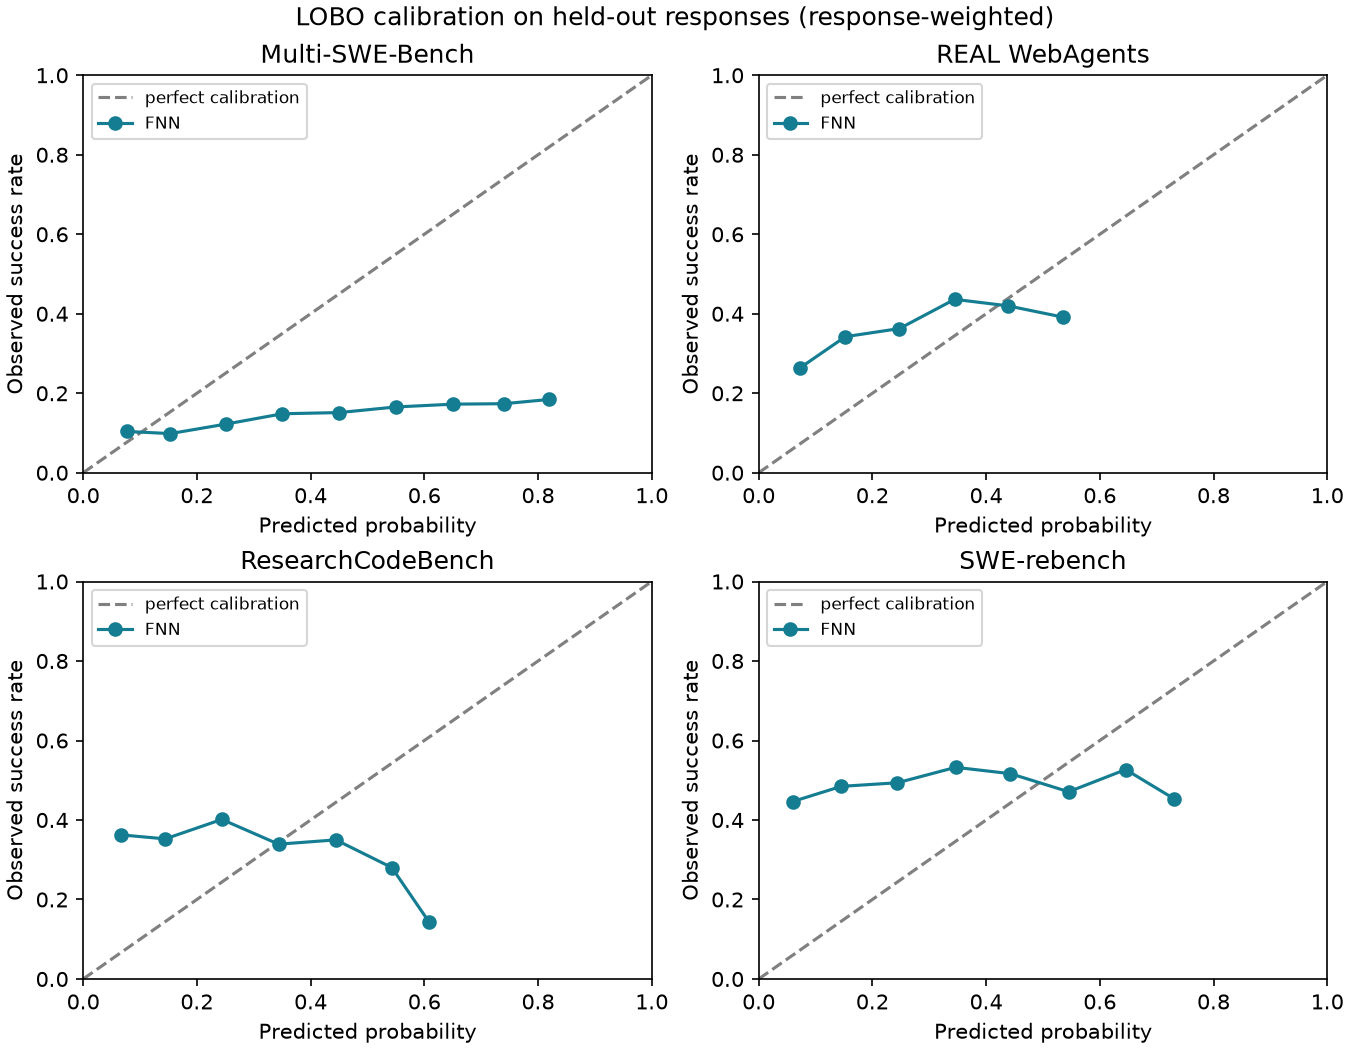

In [4]:
lobo = json.loads((HERE / 'results/lobo/summary.json').read_text())
display(pd.DataFrame(lobo['aggregate']).T.round(6))
display(pd.read_csv(HERE / 'results/lobo/fold_scores.csv').round(6))
display(pd.DataFrame(lobo['folds']))
for name in ['lobo_comparison.png', 'lobo_learning_curves.png', 'lobo_calibration.png']:
    display(Image(filename=str(HERE / 'results/lobo' / name)))

## Report Summary

The approach uses a frozen SBERT encoder to represent task text using up to four selected text windows. These embeddings are averaged and combined with model metadata and simple text statistics. A smaller FNN with hidden layers of 32 and 16 neurons predicts the probability of a correct answer. Training uses Brier loss, dropout, L2 regularization, early stopping, and learning-rate scheduling.

Local four-fold LOBO equal-pair Brier improved from 0.2840 for the original FNN to 0.2615, approximately 7.9% lower. It still performed worse than constant-0.5 predictions (0.2500) and the fitting-mean baseline (0.2318). Across three initialization seeds, familiar-benchmark validation Brier averaged 0.161223 with sample SD 0.000700. LOBO uses only one initialization seed and previously examined public benchmarks, so these results do not establish consistent improvement on new benchmarks or a CodaBench score.

## Optional Fresh Training

Leave these switches off to view the saved results. Fresh training and LOBO runs use the selected method only and write new run folders; they never replace the submission automatically. Set AIMS_DATA_DIR if the dataset is elsewhere, and AIMS_ENCODER_DIR if using another local copy of MiniLM. Initial text encoding can take several minutes.

In [5]:
RUN_TRAINING = False
RUN_LOBO = False

if RUN_TRAINING or RUN_LOBO:
    from datetime import datetime
    from dharaneesh.training import find_encoder, run_training
    from dharaneesh.build_submission import restore_encoder
    restore_encoder()
    encoder = Path(os.environ.get('AIMS_ENCODER_DIR', str(HERE / 'submission/text_encoder')))
    run_root = DATA_DIR / 'approach1_outputs/experiment_runs'
    stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    if RUN_TRAINING:
        run_training(DATA_DIR, run_root / f'combined_prompt_{stamp}', encoder)
    if RUN_LOBO:
        from dharaneesh.lobo import run_lobo
        run_lobo(DATA_DIR, run_root / f'combined_lobo_{stamp}', encoder)
else:
    print('Showing saved results. No training or submission files were changed.')

Showing saved results. No training or submission files were changed.


## Submission

Upload submission_fnn.zip manually. Its root contains model.py, the shared feature and text-window code, configuration, trained weights, requirements, and the frozen text_encoder folder. The local submission folder contains the same files. Inference evaluates the trained Dense/ReLU/sigmoid layers with NumPy and does not need TensorFlow or Keras.

The bundle uses the existing seed-42 validation-selected model fitted on 109,305 responses, not a refit on all 136,282 responses. Its validation Brier is 0.161935. No claim is made about its hidden competition score.

In [6]:
from dharaneesh.training import file_sha256
checks = json.loads((HERE / 'results/submission_checks.json').read_text())
assert file_sha256(HERE / 'submission_fnn.zip') == checks['zip_sha256']
assert file_sha256(HERE / 'results/validation/best_fnn.keras') == checks['checkpoint_sha256']
print('Submission folder:', HERE / 'submission')
print('Upload file:', HERE / 'submission_fnn.zip')
print('Compiled FNN:', HERE / 'results/validation/best_fnn.keras')
print('ZIP size (MB):', round(checks['zip_bytes'] / 1_000_000, 2))
print('Checkpoint and ZIP hashes verified.')
REBUILD_ZIP = False
if REBUILD_ZIP:
    from dharaneesh.build_submission import build
    build()

Submission folder: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\submission
Upload file: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\submission_fnn.zip
Compiled FNN: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\results\validation\best_fnn.keras
ZIP size (MB): 83.58
Checkpoint and ZIP hashes verified.
